# Plotting delay spectra
In this notebook, we show a few different ways of plotting delay spectra.

In [1]:
%matplotlib inline
from datetime import UTC, datetime

import numpy as np
from pyuvdata import UVData

import hera_pspec as hp
from hera_pspec.data import DATA_PATH

In [2]:
print(f"Running with {hp.__version__} on {datetime.now(UTC)}")

Running with 0.5.1.dev207+g9dfd7f490 on 2026-10-21 07:51:11.512990+00:00


First, we need to load some data and generate power spectra, using `PSpecData`.

In [3]:
# Load beam model
beamfile = f"{DATA_PATH}/HERA_NF_dipole_power.beamfits"
cosmo = hp.conversions.DEFAULT_COSMOLOGY
uvb = hp.pspecbeam.PSpecBeamUV(beamfile, cosmo=cosmo)

# Load data into UVData objects
dfile = f"{DATA_PATH}/zen.all.xx.LST.1.06964.uvA"
uvd = UVData()
uvd.read_miriad(dfile)

# We only have 1 data file here, so slide the time axis by one integration
# to avoid noise bias (not normally needed!)
uvd1 = uvd.select(times=np.unique(uvd.time_array)[:-1:2], inplace=False)
uvd2 = uvd.select(times=np.unique(uvd.time_array)[1::2], inplace=False)

# Create a new PSpecData object
ds = hp.PSpecData(dsets=[uvd1, uvd2], wgts=[None, None], beam=uvb)
ds.rephase_to_dset(0)  # Phase to the zeroth dataset

# Construct list of baseline pairs to calculate power spectra for
bls = [(24, 25), (37, 38), (38, 39)]
bls1, bls2, blp = hp.utils.construct_blpairs(
    bls, exclude_permutations=False, exclude_auto_bls=True
)

# Power spectrum calculation
uvp = ds.pspec(
    bls1,
    bls2,
    (0, 1),
    [("xx", "xx")],
    spw_ranges=[(300, 400), (600, 721)],
    input_data_weight="identity",
    norm="I",
    taper="blackman-harris",
    verbose=False,
)

In [4]:
blpairs = np.unique(uvp.blpair_array)

## Plot average power spectra
First, let's plot the LST- and baseline-pair-averaged power spectrum.

Baseline-pair arguments use a *groups* convention:
- Pass a flat list like `[blp1, blp2]` to plot each blpair separately.
- Wrap in a nested list like `[[blp1, blp2]]` to treat them as one averaged group.

So `[blps]` below passes all blpairs as a single group to average together.

Baseline pairs: [np.int64(124125137138), np.int64(124125138139), np.int64(137138124125), np.int64(137138138139), np.int64(138139124125), np.int64(138139137138)]


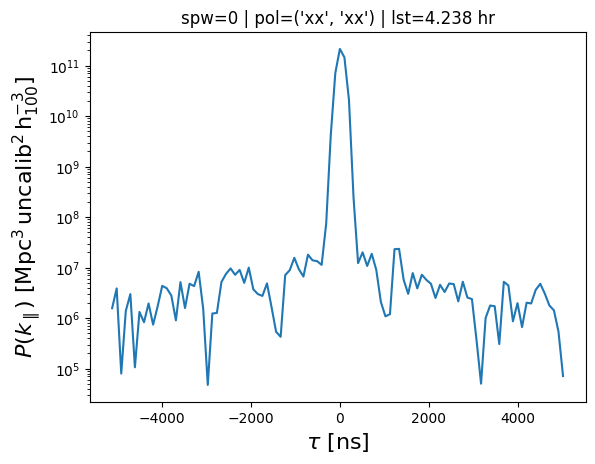

In [5]:
# Unpack the blpair integers into a plain Python list.
blps = list(blpairs)
print("Baseline pairs:", blps)

# [blps] wraps all blpairs in one group; with average_blpairs=True this
# produces a single averaged spectrum.
fig = hp.plot.delay_spectrum(
    uvp, [blps], spw=0, pol=("xx", "xx"), average_blpairs=True, average_times=True
)

The UVData files contain 3 time bins; let's average over baseline-pairs but keep the time bins intact. We can also use the shorthand `'xx'` to specify the matching polarization pair `('xx', 'xx')`.

When `average_blpairs=True` the auto-generated title omits the (potentially very long) list of averaged blpairs; only the spectral-window and polarization are shown.

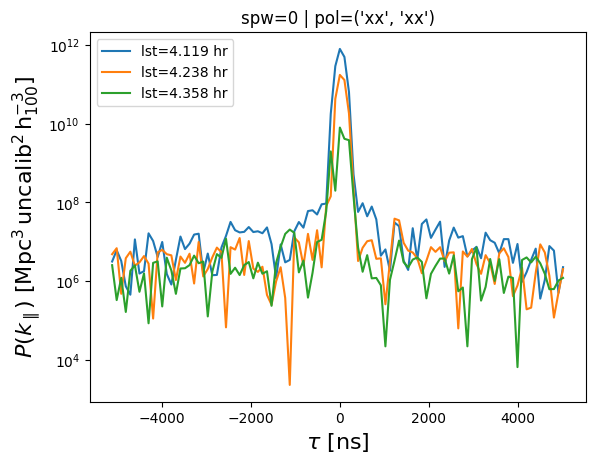

In [6]:
fig = hp.plot.delay_spectrum(
    uvp, [blps], spw=0, pol="xx", average_blpairs=True, average_times=False, legend=True
)

And now let's try the opposite: average over times, but keep the baseline-pairs separate.

Passing `blps` (a flat list of blpair integers, not wrapped) plots each baseline-pair as its own curve. Because multiple blpairs are present, `delay_spectrum` automatically moves the varying blpair label into the legend when `legend=True`.

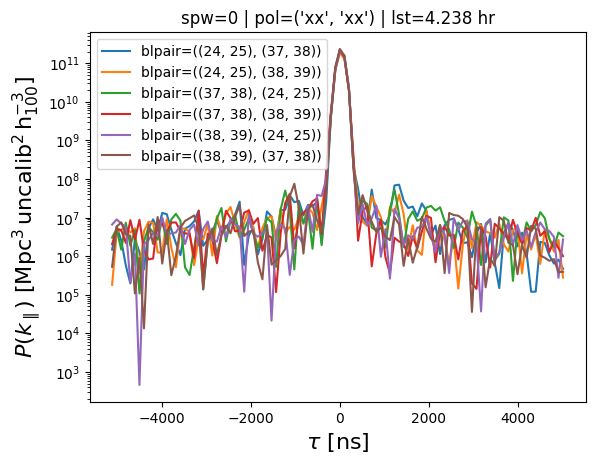

In [7]:
# Pass blps as a flat list so each blpair is plotted as a separate curve.
fig = hp.plot.delay_spectrum(
    uvp, blps, spw=0, pol="xx", average_blpairs=False, average_times=True, legend=True
)

### Legend and title

By default (`label_type='auto'`), `delay_spectrum` inspects all plotted spectra and writes *static* metadata (fields identical across all curves) to the axes title, while *varying* metadata goes to the legend.

Pass `legend=True` to display the legend. If only a single spectrum is plotted and all fields are identical, no legend entry is generated even when `legend=True`.

Use `title_legend=False` to suppress all auto-generated title/legend text (useful when composing multiple `delay_spectrum` calls onto the same axes).

## Cosmological units
Now let's plot in cosmological units instead of delay units (make sure a cosmology is set first):

self.cosmo exists and overwrite == False, not overwriting...


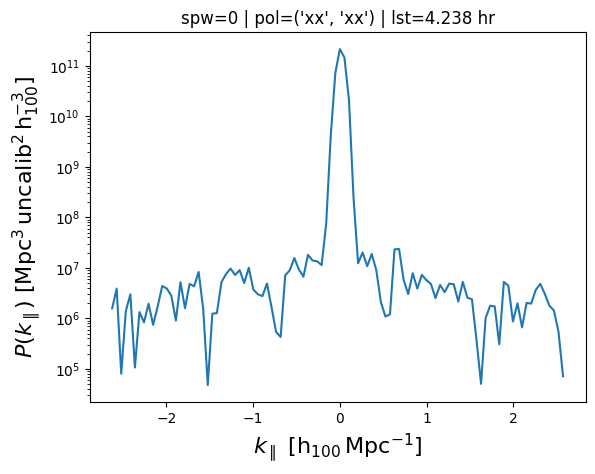

In [8]:
uvp.set_cosmology(hp.conversions.DEFAULT_COSMOLOGY)
fig = hp.plot.delay_spectrum(
    uvp, [blps], spw=0, pol="xx", average_blpairs=True, average_times=True, delay=False
)

We can also plot the dimensionless $\Delta^2$ power spectrum instead of the regular power spectrum:

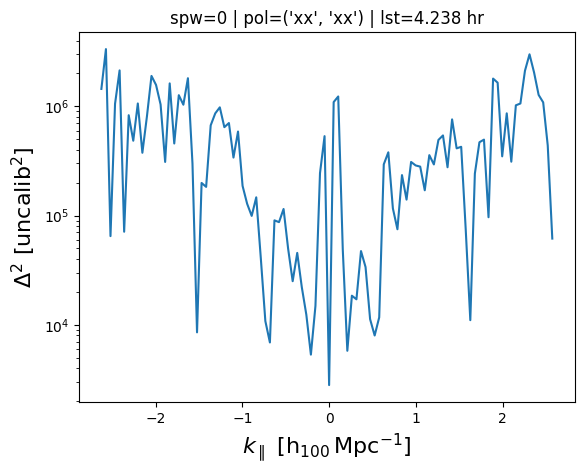

In [9]:
fig = hp.plot.delay_spectrum(
    uvp,
    [blps],
    spw=0,
    pol="xx",
    average_blpairs=True,
    average_times=True,
    delay=False,
    deltasq=True,
    legend=True,
)